<a href="https://colab.research.google.com/github/infinityrohit07/tensorflow-learning/blob/main/notebooks/15_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### What is Regression?

**Regression** is a type of supervised machine learning used to predict continuous numerical values.

The model learns the relationship between input features (`X`) and output labels (`y`) using training data.

**Examples:**
- Predicting house prices.
- Predicting temperature.
- Predicting car prices.
- Predicting employee salaries.

#### Regression vs Classification

| Regression | Classification |
|---|---|
| Predicts numerical values | Predicts categories or classes |
| Example: House price | Example: Spam or not spam |
| Output: ₹50 lakh | Output: Spam |

### Understanding Features (X) and Labels (y)

In supervised learning:

- **X (Features):** Input data used by the model to make predictions.
- **y (Labels):** Actual output values the model needs to learn to predict.
- **ŷ (Predictions):** Output predicted by the trained model.

Example:

| House Size (X) | House Price (y) |
|---:|---:|
| 500 sq ft | ₹25 lakh |
| 800 sq ft | ₹40 lakh |
| 1000 sq ft | ₹50 lakh |
| 1200 sq ft | ₹60 lakh |
| 1500 sq ft | ₹75 lakh |

Here, house size is the feature, and house price is the label.

### Relationship Between Features and Labels

A regression model tries to learn the relationship between input features and output values.

For example:

| House Size (X) | House Price (y) |
|---:|---:|
| 500 | 25 |
| 800 | 40 |
| 1000 | 50 |
| 1200 | 60 |
| 1500 | 75 |

<br>

The relationship can be represented by:

$$
y = 0.05x
$$

If the house size is 2000 sq ft:

$$
y = 0.05 \times 2000 = 100
$$

The predicted price is ₹100 lakh.

#### Types of Relationships

- **Positive relationship:** As X increases, Y tends to increase.
- **Negative relationship:** As X increases, Y tends to decrease.
- **No relationship:** Changes in X do not show a clear relationship with Y.

### Visualizing Regression Data

We can use a scatter plot to visualize the relationship between features and labels.

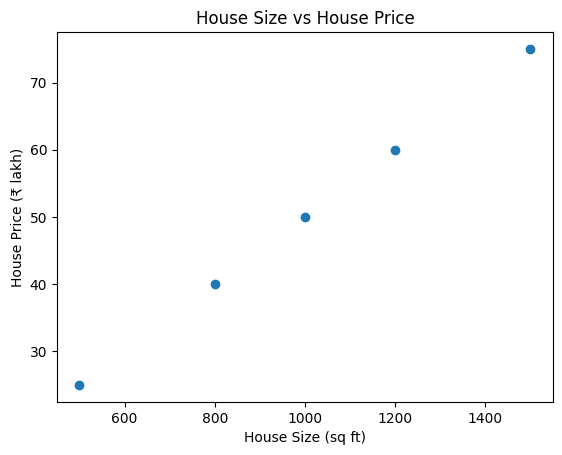

In [ ]:
import matplotlib.pyplot as plt

X = [500, 800, 1000, 1200, 1500]
y = [25, 40, 50, 60, 75]

plt.scatter(X, y)

plt.xlabel("House Size (sq ft)")
plt.ylabel("House Price (₹ lakh)")
plt.title("House Size vs House Price")

plt.show()

as the house size increases, the price also increases.

### Understanding the Regression Line

A **regression line** represents the relationship between input features and output values.

For simple linear regression, we use:

$$
\hat{y} = mx + b
$$

Where:

- `ŷ` = Predicted output
- `x` = Input feature
- `m` = Slope
- `b` = Intercept

#### Slope and Intercept

**Slope (m):**

- Tells us how much the predicted output changes when the input increases by one unit.
- Controls the steepness and direction of the regression line.

**Intercept (b):**

- Represents the predicted output when the input is zero.
- Determines where the regression line crosses the y-axis.

Example:

$$
\hat{y} = 3x + 7
$$

- Slope = 3
- Intercept = 7

#### Types of Slopes

- **Positive slope:** The line rises from left to right.
- **Negative slope:** The line falls from left to right.
- **Zero slope:** The line is horizontal.

#### Connection to a Neural Network

A single neuron also uses a similar equation:

$$
\hat{y} = wx + b
$$

- `w` = Weight (similar to slope)
- `b` = Bias (similar to intercept)

### How Does a Model Learn Slope and Intercept?

A model is not directly given the correct equation. It learns the weight and bias during training.

Example training data:

| X | y |
|---:|---:|
| 1 | 15 |
| 2 | 25 |
| 3 | 35 |
| 4 | 45 |
| 5 | 55 |

The actual relationship is:

$$
y = 10x + 5
$$

<br>

During training:

1. The model starts with initial weight and bias values.
2. It makes predictions.
3. It calculates the loss by comparing predictions with actual values.
4. The optimizer adjusts the weight and bias to reduce the loss.
5. This process repeats to improve predictions.

<br>

The model should eventually learn values close to:

$$
w = 10,\quad b = 5
$$

### Making Predictions

Once the model learns its weight and bias, it can use them to predict outputs for new inputs.

Suppose the learned equation is:

$$
\hat{y} = 10x + 5
$$

For input `x = 6`:

$$
\hat{y} = 10(6) + 5 = 65
$$

<br>

Other predictions:

| Input (x) | Prediction (ŷ) |
|---:|---:|
| 6 | 65 |
| 7 | 75 |
| 8 | 85 |
| 9 | 95 |
| 10 | 105 |

### Generalization

**Generalization** is the ability of a trained model to make accurate predictions on new, unseen data.

For example, if a model learns the relationship between house size and house price using existing training data, it should also be able to predict the price of a house size it has never seen before.

A good regression model should not simply memorize training data. It should learn the underlying relationship.


### Building a Simple Linear Regression Model Using TensorFlow

We'll take the equation we've been working with:
$$
y = 10x + 5
$$

And teach a TensorFlow model to learn this relationship from training data.

#### Importing TensorFlow and Checking Installed Version

In [ ]:
import tensorflow as tf
print(tf.__version__)

2.21.0


#### Creating training data

In [ ]:
X = tf.constant([1, 2, 3, 4, 5], dtype=tf.float32) # features
y = tf.constant([15, 25, 35, 45, 55], dtype=tf.float32) # labels

In [ ]:
X,y

(<tf.Tensor: shape=(5,), dtype=float32, numpy=array([1., 2., 3., 4., 5.], dtype=float32)>,
 <tf.Tensor: shape=(5,), dtype=float32, numpy=array([15., 25., 35., 45., 55.], dtype=float32)>)

In [ ]:
print(X.shape, y.shape)

(5,) (5,)


**Understanding the shape**

Keras expects the input data to follow this structure:
$$
(\text{samples},\text{features})
$$

- A sample is one individual example in our dataset.
- A feature is an input property that the model uses to make a prediction.

We have 5 examples. And 1 feature i.e. X.

Therefore:
$$
\boxed{(5,1)}
$$

is required.


In [ ]:
X = tf.reshape(X, shape=(5, 1))

print(X)
print(X.shape)

tf.Tensor(
[[1.]
 [2.]
 [3.]
 [4.]
 [5.]], shape=(5, 1), dtype=float32)
(5, 1)


#### Building our regression model

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Dense(1)
])

Let's understand the two components:
1. tf.keras.Sequential: Creates a model where layers are arranged sequentially.
2. Dense(1): Creates a fully connected layer with one neuron.

In [ ]:
model.build(input_shape=(None, 1))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    loss=tf.keras.losses.MeanAbsoluteError(),
    optimizer=tf.keras.optimizers.SGD(),
    metrics=["mae"]
)

In [ ]:
model.fit(X, y, epochs=100)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 802ms/step - loss: 32.3709 - mae: 32.3709
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 32.2710 - mae: 32.2710
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 32.1710 - mae: 32.1710
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 32.0710 - mae: 32.0710
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 31.9710 - mae: 31.9710
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 31.8710 - mae: 31.8710
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - loss: 31.7710 - mae: 31.7710
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 31.6710 - mae: 31.6710
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 31.5710 - mae: 31.5710
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 31.4710 - mae: 31.4710
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 31.3710 - mae: 31.3710
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 31.2710 - mae: 31.2710
Epoch 13/100
1/1 ━━━━━━━

In [ ]:
# Get the learned weights and bias
model.get_weights()

[array([[3.876346]], dtype=float32), array([0.99999934], dtype=float32)]

Its current prediction equation is:
$$
\boxed{\hat{y}=3.876x+1}
$$

But remember, our actual relationship is:
$$
y=10x+5
$$

So the model hasn't learned the correct relationship yet.

We used SGD with its default learning rate of 0.01.

This means the optimizer is making relatively small updates to the weight and bias.

We trained for 100 epochs, but the model still needs improvement.

**Important:** The model is learning. We can see that because the loss decreased during training. However, decreasing loss doesn't automatically mean the model has learned an accurate relationship.

In [ ]:
# Make predictions using our trained model
y_pred = model.predict(X)

print(y_pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
[[ 4.8763456]
 [ 8.752691 ]
 [12.629037 ]
 [16.505384 ]
 [20.381731 ]]


we didn't get the correct predictions.

In [ ]:
print("Actual values:", y.numpy())
print("Predicted values:", y_pred.flatten())

Actual values: [15. 25. 35. 45. 55.]
Predicted values: [ 4.8763456  8.752691  12.629037  16.505384  20.381731 ]


**Improving the model**

We trained for 100 epochs, but the model hasn't learned the relationship accurately yet.

Let's continue training the existing model for another 300 epochs.

In [ ]:
history = model.fit(X, y, epochs=300)

Epoch 1/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 22.3710 - mae: 22.3710
Epoch 2/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 22.2710 - mae: 22.2710
Epoch 3/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - loss: 22.1710 - mae: 22.1710
Epoch 4/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - loss: 22.0710 - mae: 22.0710
Epoch 5/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - loss: 21.9710 - mae: 21.9710
Epoch 6/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 21.8710 - mae: 21.8710
Epoch 7/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 21.7710 - mae: 21.7710
Epoch 8/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 21.6710 - mae: 21.6710
Epoch 9/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 21.5710 - mae: 21.5710
Epoch 10/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 21.4710 - mae: 21.4710
Epoch 11/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 21.3710 - mae: 21.3710
Epoch 12/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 21.2710 - mae: 21.2710
Epoch 13/300
1/1 ━━━━━━━

In [ ]:
# Checking updated weight and bias
print("Weights and bias:", model.get_weights())

# Making new predictions
y_pred = model.predict(X)

print("Actual values:", y.numpy())
print("Predicted values:", y_pred.flatten())

Weights and bias: [array([[10.384382]], dtype=float32), array([3.4600036], dtype=float32)]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Actual values: [15. 25. 35. 45. 55.]
Predicted values: [13.844386 24.228767 34.61315  44.99753  55.381916]


Our actual equation is:
$$
y=10x+5
$$

The model has learned:
$$
\boxed{\hat{y}=10.384x+3.46}
$$

The model learned a much better relationship by repeatedly adjusting its weight and bias.

**Visualizing Actual vs Predicted Values**

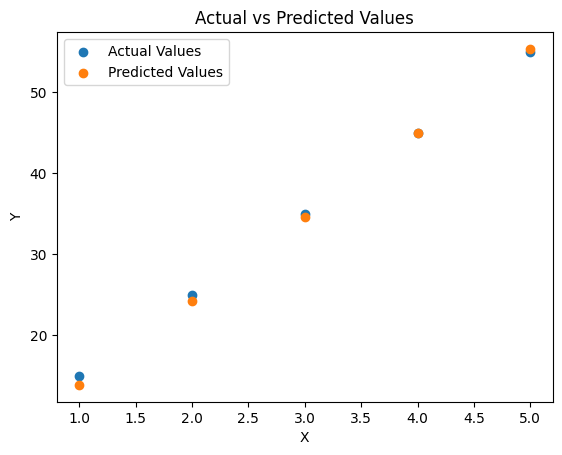

In [ ]:
plt.scatter(X.numpy(), y.numpy(), label="Actual Values")

plt.scatter(
    X.numpy(),
    y_pred.flatten(),
    label="Predicted Values"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Actual vs Predicted Values")

plt.legend()
plt.show()

In [ ]:
mae = tf.keras.losses.MeanAbsoluteError()

mae_value = mae(y, tf.squeeze(y_pred))

print("Mean Absolute Error:", mae_value.numpy())

Mean Absolute Error: 0.5396158


Why tf.squeeze(y_pred)?
- y has shape (5,).
- y_pred has shape (5, 1).
- tf.squeeze() removes the extra dimension, making the shapes compatible: (5,).

### Another Regression Model with Training and Testing Data Splitting

#### Dataset X = feature and y = label

In [ ]:
X = [[1], [2], [3], [4], [5]]
y = [15, 25, 35, 45, 55]

#### Splitting data into 80% (training data) - 20% (testing data)

In [ ]:
X_train = tf.constant(X[:4])
y_train = tf.constant(y[:4])

X_test = tf.constant(X[4:])
y_test = tf.constant(y[4:])

#### Checking the data division in training and testing

In [ ]:
print("Training inputs:", X_train.numpy())
print("Training labels:", y_train.numpy())

print("Testing inputs:", X_test.numpy())
print("Testing labels:", y_test.numpy())

Training inputs: [[1]
 [2]
 [3]
 [4]]
Training labels: [15 25 35 45]
Testing inputs: [[5]]
Testing labels: [55]


#### Training a fresh new model

In [ ]:
model_2 = tf.keras.Sequential([
    tf.keras.layers.Dense(1)
])

model_2.compile(
    loss=tf.keras.losses.MeanAbsoluteError(),
    optimizer=tf.keras.optimizers.SGD(),
    metrics=["mae"]
)

In [ ]:
history_2 = model_2.fit(X_train, y_train, epochs=100)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 995ms/step - loss: 30.3109 - mae: 30.3109
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - loss: 30.2384 - mae: 30.2384
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - loss: 30.1659 - mae: 30.1659
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 30.0934 - mae: 30.0934
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 30.0209 - mae: 30.0209
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 29.9484 - mae: 29.9484
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 29.8759 - mae: 29.8759
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 29.8034 - mae: 29.8034
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - loss: 29.7309 - mae: 29.7309
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - loss: 29.6584 - mae: 29.6584
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - loss: 29.5859 - mae: 29.5859
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step - loss: 29.5134 - mae: 29.5134
Epoch 13/100
1/1 ━━

In [ ]:
print("Weights and bias:", model_2.get_weights())

Weights and bias: [array([[2.3756216]], dtype=float32), array([0.99999934], dtype=float32)]


In [ ]:
train_predictions = model_2.predict(X_train)

print("Actual:", y_train.numpy())
print("Predicted:", train_predictions.flatten())

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
Actual: [15 25 35 45]
Predicted: [ 3.3756208  5.7512426  8.1268635 10.502485 ]


our model doesn't predict the expected output even as close as it should. the model's predictions are significantly different from the actual values, indicating that it hasn't learned the relationship between X and y sufficiently yet.

In [ ]:
print(X_train.shape)
print(y_train.shape)

(4, 1)
(4,)


In [ ]:
y_train = tf.reshape(y_train, shape=(4, 1))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (4, 1)
y_train shape: (4, 1)


In [ ]:
y_train = tf.squeeze(y_train)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (4, 1)
y_train: (4,)


the above three code cells are useless ignore it. i did something stupid and i undo it.

In [ ]:
history_2 = model_2.fit(X_train, y_train, epochs=300)

Epoch 1/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 23.0609 - mae: 23.0609
Epoch 2/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 22.9884 - mae: 22.9884
Epoch 3/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - loss: 22.9159 - mae: 22.9159
Epoch 4/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - loss: 22.8434 - mae: 22.8434
Epoch 5/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - loss: 22.7709 - mae: 22.7709
Epoch 6/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - loss: 22.6984 - mae: 22.6984
Epoch 7/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - loss: 22.6259 - mae: 22.6259
Epoch 8/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - loss: 22.5534 - mae: 22.5534
Epoch 9/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - loss: 22.4809 - mae: 22.4809
Epoch 10/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 22.4084 - mae: 22.4084
Epoch 11/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 22.3359 - mae: 22.3359
Epoch 12/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 22.2634 - mae: 22.2634
Epoch 13/300
1/1 ━━━━

trained the model for another 300 epochs to reducce its loss.

In [ ]:
# Check learned weight and bias
print("Weights and bias:", model_2.get_weights())

# Make predictions on training data
train_predictions = model_2.predict(X_train)

print("Actual:", y_train.numpy())
print("Predicted:", train_predictions.flatten())

Weights and bias: [array([[9.875614]], dtype=float32), array([3.9999967], dtype=float32)]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
Actual: [15 25 35 45]
Predicted: [13.87561  23.751225 33.62684  43.502453]


quite close to expected output but not yet close.

In [ ]:
# Predict using unseen testing data
test_predictions = model_2.predict(X_test)

print("Actual value:", y_test.numpy())
print("Predicted value:", test_predictions.flatten())

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Actual value: [55]
Predicted value: [53.378067]


hmm.. as i said close but not close enough. it still needs improvement. but i know u know by now how to improve a model, right?

In [ ]:
# Reshape actual and predicted values
y_test_reshaped = tf.reshape(y_test, (1, 1))

# Calculate test MAE
mae_test = test_mae(y_test_reshaped, test_predictions)

print("Test MAE:", mae_test.numpy())

Test MAE: 1.621933


evaluated test prediction using mae.

In [ ]:
# Evaluate the model on unseen test data
model_2.evaluate(X_test, y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - loss: 1.6219 - mae: 1.6219


[1.6219329833984375, 1.6219329833984375]

In [ ]:
# Continue training for another 100 epochs
history_more = model_2.fit(
    X_train,
    y_train,
    epochs=100
)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 1.3110 - mae: 1.3110
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 1.2385 - mae: 1.2385
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - loss: 1.1660 - mae: 1.1660
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - loss: 1.0935 - mae: 1.0935
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - loss: 1.0210 - mae: 1.0210
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - loss: 0.9485 - mae: 0.9485
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - loss: 0.8760 - mae: 0.8760
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 268ms/step - loss: 0.8035 - mae: 0.8035
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - loss: 0.7310 - mae: 0.7310
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.6585 - mae: 0.6585
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.5860 - mae: 0.5860
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.5135 - mae: 0.5135
Epoch 13/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms

In [ ]:
model_2.evaluate(X_test, y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.3680 - mae: 0.3680


[0.3680458068847656, 0.3680458068847656]

In [ ]:
# Check prediction after additional training
new_test_predictions = model_2.predict(X_test)

print("Actual:", y_test.numpy())
print("New prediction:", new_test_predictions.flatten())
print("Updated weights and bias:", model_2.get_weights())

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Actual: [55]
New prediction: [55.368046]
Updated weights and bias: [array([[10.190608]], dtype=float32), array([4.415006], dtype=float32)]


After training for another 100 epochs, the test MAE decreased from 1.6219 to 0.3680. The learned weight and bias also moved closer to the expected values of 10 and 5. This demonstrates how additional training can improve a model's predictions.